In [53]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from dotenv import load_dotenv
from groq import Groq

load_dotenv()
groq_client = Groq()

In [54]:
class BlogState(TypedDict):
    title: str
    outline: str
    blog: str
    rate: bool

graph = StateGraph(BlogState)

In [55]:
def ask_groq(query: str) -> str:
    """Handles the raw API communication with Groq."""
    try:
        completion = groq_client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            messages=[
                {"role": "user", "content": query}
            ],
            temperature=0.7
        )
        return completion.choices[0].message.content
    except Exception as e:
        # Handle API errors gracefully
        return f"Error communicating with Groq: {str(e)}"


def generate_outline(state: BlogState) -> BlogState:
    title = state["title"]
    outline = ask_groq(f"Create a clear, well-structured outline for a blog post titled: {title}.\nOrganize the ideas in a logical sequence using main sections and concise supporting points. Keep every point relevant to the title, and do not write the full blog post.\nReturn only the outline, with no introduction or commentary.\nMaximum length: 100 words")

    state["outline"] = outline
    
    return state


def generate_blog(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    blog = ask_groq(f"Write a clear, engaging, and well-structured blog post using the title and outline below.\nTitle: {title}\nOutline: {outline}\nFollow the outline in order, develop each point coherently, and use natural language with smooth transitions. Avoid repetition, unsupported claims, and unnecessary filler.\nReturn only the finished blog post, with no preface or commentary.\nMaximum length: 200 words")

    state["blog"] = blog

    return state


def rate_blog(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    blog = state["blog"]

    rate = int(ask_groq(f"Evaluate the quality of the blog post below on a scale from 1 to 10, where 1 is very poor and 10 is excellent. Assess relevance to the title and outline, clarity, structure, coherence, grammar, readability, and usefulness. Consider the actual blog content when assigning the score.\nTitle: {title}\nOutline: {outline}\nBlog: {blog}\nReturn only one integer from 1 to 10, with no explanation or extra text."))

    state["rate"] = rate

    return state

    

In [56]:
graph.add_node("generate_outline", generate_outline)
graph.add_node("generate_blog", generate_blog)
graph.add_node("rate_blog", rate_blog)

In [57]:
graph.add_edge(START, "generate_outline")
graph.add_edge("generate_outline", "generate_blog")
graph.add_edge("generate_blog","rate_blog")
graph.add_edge("rate_blog", END)

In [58]:
workflow = graph.compile()

In [59]:
initial_state = {"title":"Small Steps, Big Changes: How to Make Every Day Count"}
final_state = workflow.invoke(initial_state)

print(final_state)

{'title': 'Small Steps, Big Changes: How to Make Every Day Count', 'outline': 'I. Introduction: Embracing the Power of Micro-Progress\n    A. The myth of overnight success\n    B. Why consistency beats intensity\n\nII. The Science of Small Habits\n    A. Compound effects over time\n    B. Lowering the barrier to entry\n\nIII. Practical Strategies for Daily Impact\n    A. The Two-Minute Rule\n    B. Habit stacking and environmental design\n    C. Focusing on identity-based changes\n\nIV. Overcoming Obstacles\n    A. Managing motivation dips\n    B. The power of self-forgiveness\n\nV. Conclusion: Cumulative Growth\n    A. Visualizing long-term results\n    B. Calling for immediate action', 'blog': 'The myth of overnight success distracts us from a simpler truth: consistency beats intensity. We often wait for massive inspiration, ignoring the power of micro-progress.\n\nScience supports small habits. Through compound effects, tiny actions accumulate into significant results over time. Mor

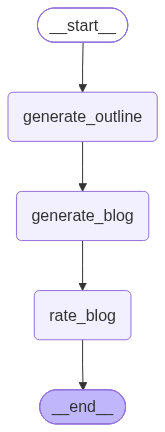

In [60]:
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())

# only works in jupyter nb